In [21]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# 1. Загрузка данных регрессии
housing = fetch_california_housing(as_frame=True)
X, y = housing.data, housing.target

# 2. Разбиение на train/test ДО любых вычислений (защита от утечки)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Пайплайн предобработки (заполнение + масштабирование)
numeric_features = list(X.columns)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[('num', numeric_transformer, numeric_features)]
)

# Применяем предобработку к данным
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print(f"Размер тренировочной матрицы: {X_train_scaled.shape}")
print(f"Размер тестовой матрицы: {X_test_scaled.shape}")

Размер тренировочной матрицы: (16512, 8)
Размер тестовой матрицы: (4128, 8)


In [22]:
class ScratchLinearRegression:
    def __init__(self, lr=0.01, epochs=500):
        self.lr = lr
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.loss_history = []
        
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        y = np.array(y)
        
        for _ in range(self.epochs):
            # Предсказания модели
            y_pred = np.dot(X, self.weights) + self.bias
            
            # Функция потерь MSE
            loss = np.mean((y_pred - y) ** 2)
            self.loss_history.append(loss)
            
            # Градиенты
            dw = (2 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (2 / n_samples) * np.sum(y_pred - y)
            
            # Обновление параметров
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
            
    def predict(self, X):
        return np.dot(X, self.weights) + self.bias

# Обучаем нашу модель с нуля
custom_lr = ScratchLinearRegression(lr=0.05, epochs=300)
custom_lr.fit(X_train_scaled, y_train)

print("Обучение кастомной модели завершено!")

Обучение кастомной модели завершено!


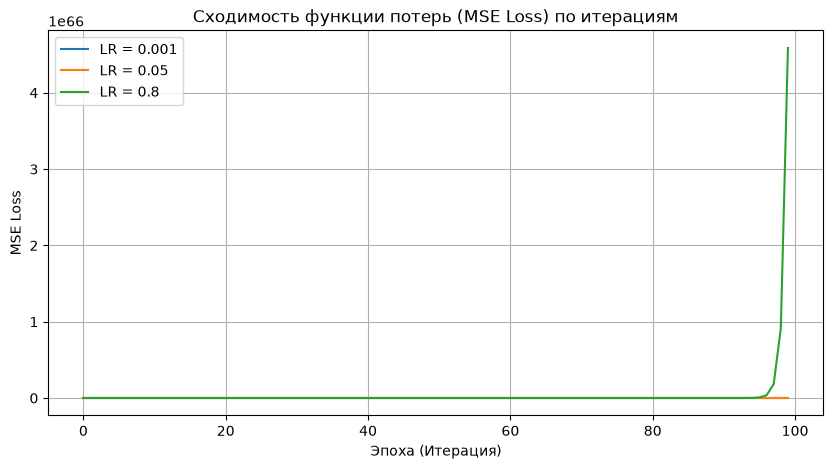

In [23]:
# Исследуем три разных learning rate
learning_rates = [0.001, 0.05, 0.8]
plt.figure(figsize=(10, 5))

for lr in learning_rates:
    model = ScratchLinearRegression(lr=lr, epochs=100)
    model.fit(X_train_scaled, y_train)
    plt.plot(model.loss_history, label=f'LR = {lr}')

plt.title('Сходимость функции потерь (MSE Loss) по итерациям')
plt.xlabel('Эпоха (Итерация)')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
# Обучаем sklearn модель
sklearn_model = LinearRegression()
sklearn_model.fit(X_train_scaled, y_train)

# Предсказания
y_pred_custom = custom_lr.predict(X_test_scaled)
y_pred_sklearn = sklearn_model.predict(X_test_scaled)

# Метрики для кастомной модели
mse_custom = mean_squared_error(y_test, y_pred_custom)
mae_custom = mean_absolute_error(y_test, y_pred_custom)
r2_custom = r2_score(y_test, y_pred_custom)

print("--- Результаты кастомной модели (NumPy) ---")
print(f"MSE: {mse_custom:.4f}")
print(f"MAE: {mae_custom:.4f} (в среднем ошибаемся на ~{mae_custom*100000:.0f}$ в стоимости жилья)")
print(f"R²:  {r2_custom:.4f}")

print("\n--- Результаты Scikit-Learn модели ---")
print(f"MSE: {mean_squared_error(y_test, y_pred_sklearn):.4f}")
print(f"R²:  {r2_score(y_test, y_pred_sklearn):.4f}")

--- Результаты кастомной модели (NumPy) ---
MSE: 0.5549
MAE: 0.5328 (в среднем ошибаемся на ~53283$ в стоимости жилья)
R²:  0.5766

--- Результаты Scikit-Learn модели ---
MSE: 0.5559
R²:  0.5758


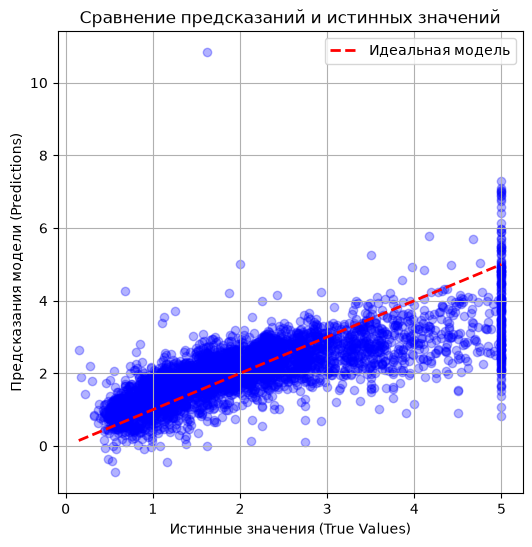

In [25]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_custom, alpha=0.3, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Идеальная модель')
plt.xlabel('Истинные значения (True Values)')
plt.ylabel('Предсказания модели (Predictions)')
plt.title('Сравнение предсказаний и истинных значений')
plt.legend()
plt.grid(True)
plt.show()

## Интерпретация результатов
1. **MAE (Средняя абсолютная ошибка):** Показывает среднее отклонение предсказания от реальной цены. Так как целевая метрика в датасете выражена в сотнях тысяч долларов, значение MAE отражает реальную денежную погрешность модели.
2. **R² (Коэффициент детерминации):** Значение близкое к 0.6–0.65 на тестовой выборке говорит о том, что модель объясняет около 60% дисперсии данных, что является неплохим результатом для базовой линейной регрессии без ручного отбора признаков.
3. **Коэффициенты:** Из-за применения `StandardScaler` веса модели показывают относительную важность признаков (чем больше модуль веса после стандартизации, тем сильнее признак влияет на стоимость жилья).